# Previsão de Demanda — Produtos AY
## Walk-Forward Validation | Holt-Winters · SARIMA · XGBoost · Prophet

**Objetivo:** Prever a demanda mensal dos 5 produtos de classe AY para os próximos 3 meses, selecionando automaticamente o modelo de menor erro por produto.

| Parâmetro | Valor |
|---|---|
| Produtos analisados | 5 (classe AY — alta prioridade, demanda variável) |
| Janela de validação | Walk-forward — 6 passos temporais |
| Métrica de seleção | MAPE (menor erro percentual absoluto médio) |
| Horizonte de previsão | 3 meses |

---


## Horizonte de Previsão — Justificativa dos 3 Meses

O horizonte de 3 meses foi escolhido por adequação ao perfil AY: produtos com
demanda errática perdem confiabilidade de previsão rapidamente, tornando janelas
mais longas pouco confiáveis no nível de SKU. Como o objetivo é operacional —
alimentar o cálculo de ES e PP —, o curto prazo equilibra acurácia e utilidade
prática, alinhado à recomendação de Silver, Pyke e Thomas (2017) para itens de
alta variabilidade.

In [ ]:
import warnings
warnings.filterwarnings('ignore')
import logging
logging.getLogger('prophet').setLevel(logging.WARNING)
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from scipy import stats
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

try:
    from prophet import Prophet
    PROPHET_OK = True
except ImportError:
    PROPHET_OK = False
    print('Prophet nao instalado. Execute: pip install prophet')

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
print('Bibliotecas carregadas!')


Importing plotly failed. Interactive plots will not work.


Bibliotecas carregadas!


### Preparação da modelagem da Previsao

In [ ]:
N_TEST    = 6   # meses usados na janela de walk-forward
HORIZONTE = 3   # meses a prever

# Carregamento
df_raw  = pd.read_csv('data/base_tratada.csv')
df_raw['data_pedido'] = pd.to_datetime(df_raw['data_pedido'])

abc_xyz = pd.read_csv('data/classificacao_abc_xyz.csv')
df_ay   = abc_xyz[abc_xyz['classe_abcxyz'] == 'AY'].copy()
IDS_AY  = df_ay['id_produto'].tolist()
NOMES   = dict(zip(df_ay['id_produto'], df_ay['produto']))


Com base nos 36 meses de histórico disponível (janeiro/2022 a dezembro/2024), a janela de validação foi definida em 6 passos temporais como equilíbrio entre representatividade do teste e suficiência dos dados de treino. Os modelos estatísticos sazonais utilizados — Holt-Winters e SARIMA com periodicidade 12 — exigem no mínimo dois ciclos sazonais completos (24 meses) para estimar seus parâmetros com confiabilidade; com N_TEST = 6, o menor conjunto de treino utilizado contém 30 meses, mantendo margem segura acima desse limite. Além disso, seis meses de teste cobrem diferentes fases do ciclo sazonal anual — incluindo tanto períodos de pico quanto de baixa demanda — tornando o MAPE resultante mais representativo do erro real do modelo ao longo do ano, ao contrário de janelas menores (como 3 meses) que poderiam concentrar os testes em um único padrão sazonal e subestimar o erro. Por fim, seis pontos de comparação oferecem estabilidade estatística suficiente para que a métrica não seja distorcida por um único mês atípico, o que é uma preocupação real em séries de classe Y com coeficiente de variação entre 0,21 e 0,40

## 1. Séries de Demanda Mensal por Produto


In [ ]:
def build_series(df, pid):
    s = (
        df[df['id_produto'] == pid]
        .groupby(['ano', 'mes'])['quantidade_pedida']
        .sum()
        .reset_index()
        .rename(columns={'ano': 'year', 'mes': 'month'})
    )
    s['data'] = pd.to_datetime(s[['year', 'month']].assign(day=1))
    result = s.sort_values('data').set_index('data')['quantidade_pedida'].rename(pid)
    return result.asfreq('MS')


series = {pid: build_series(df_raw, pid) for pid in IDS_AY}

print(f'{'Produto':<30} {'N':>4} {'Media':>8} {'Std':>8} {'CV':>6} {'Min':>8} {'Max':>8}')
print('-' * 78)
for pid, s in series.items():
    print(f'{NOMES[pid]:<30} {len(s):>4} {s.mean():>8,.0f} {s.std():>8,.0f} '
          f'{s.std()/s.mean():>6.2f} {s.min():>8,.0f} {s.max():>8,.0f}')


Produto                           N    Media      Std     CV      Min      Max
------------------------------------------------------------------------------
Luva de Proteção CA              36   40,986    9,700   0.24   23,779   64,188
Óculos de Segurança              36   40,707    8,713   0.21   23,862   58,355
Protetor Auricular               36   40,506    9,725   0.24   21,692   60,926
Filtro de Linha Industrial       36    3,549    1,420   0.40    1,629    7,487
Capacete de Segurança            36    3,454      958   0.28    1,751    5,450


## Séries de Demanda Mensal por Produto — Itens AY

### Estatísticas Descritivas (36 meses)

| Produto                    | N  | Média/mês | Std    | CV   | Mínimo | Máximo |
|----------------------------|----|:---------:|:------:|:----:|:------:|:------:|
| Luva de Proteção CA        | 36 | 40.986    | 9.700  | 0,24 | 23.779 | 64.188 |
| Óculos de Segurança        | 36 | 40.707    | 8.713  | 0,21 | 23.862 | 58.355 |
| Protetor Auricular         | 36 | 40.506    | 9.725  | 0,24 | 21.692 | 60.926 |
| Filtro de Linha Industrial | 36 | 3.549     | 1.420  | 0,40 | 1.629  | 7.487  |
| Capacete de Segurança      | 36 | 3.454     | 958    | 0,28 | 1.751  | 5.450  |

---

### Observações

- **Luva, Óculos e Protetor Auricular** têm demanda média mensal muito similar
  (~40.500–41.000 un.) — os três dominam o volume do grupo AY.
- **Filtro de Linha Industrial** apresenta o maior CV (0,40) — a demanda mais
  imprevisível proporcionalmente, variando de 1.629 a 7.487 un./mês.
- **Protetor Auricular e Luva de Proteção CA** têm os maiores desvios absolutos
  (~9.700 un.) — confirma a alta volatilidade já identificada nas análises anteriores.
- **Capacete de Segurança** é o mais estável do grupo (CV = 0,28 e menor
  desvio absoluto), mesmo sendo classificado como giro médio.
- A amplitude entre mínimo e máximo é expressiva em todos os produtos
  — reforça a necessidade de estoque de segurança robusto para absorver
  os picos de demanda.

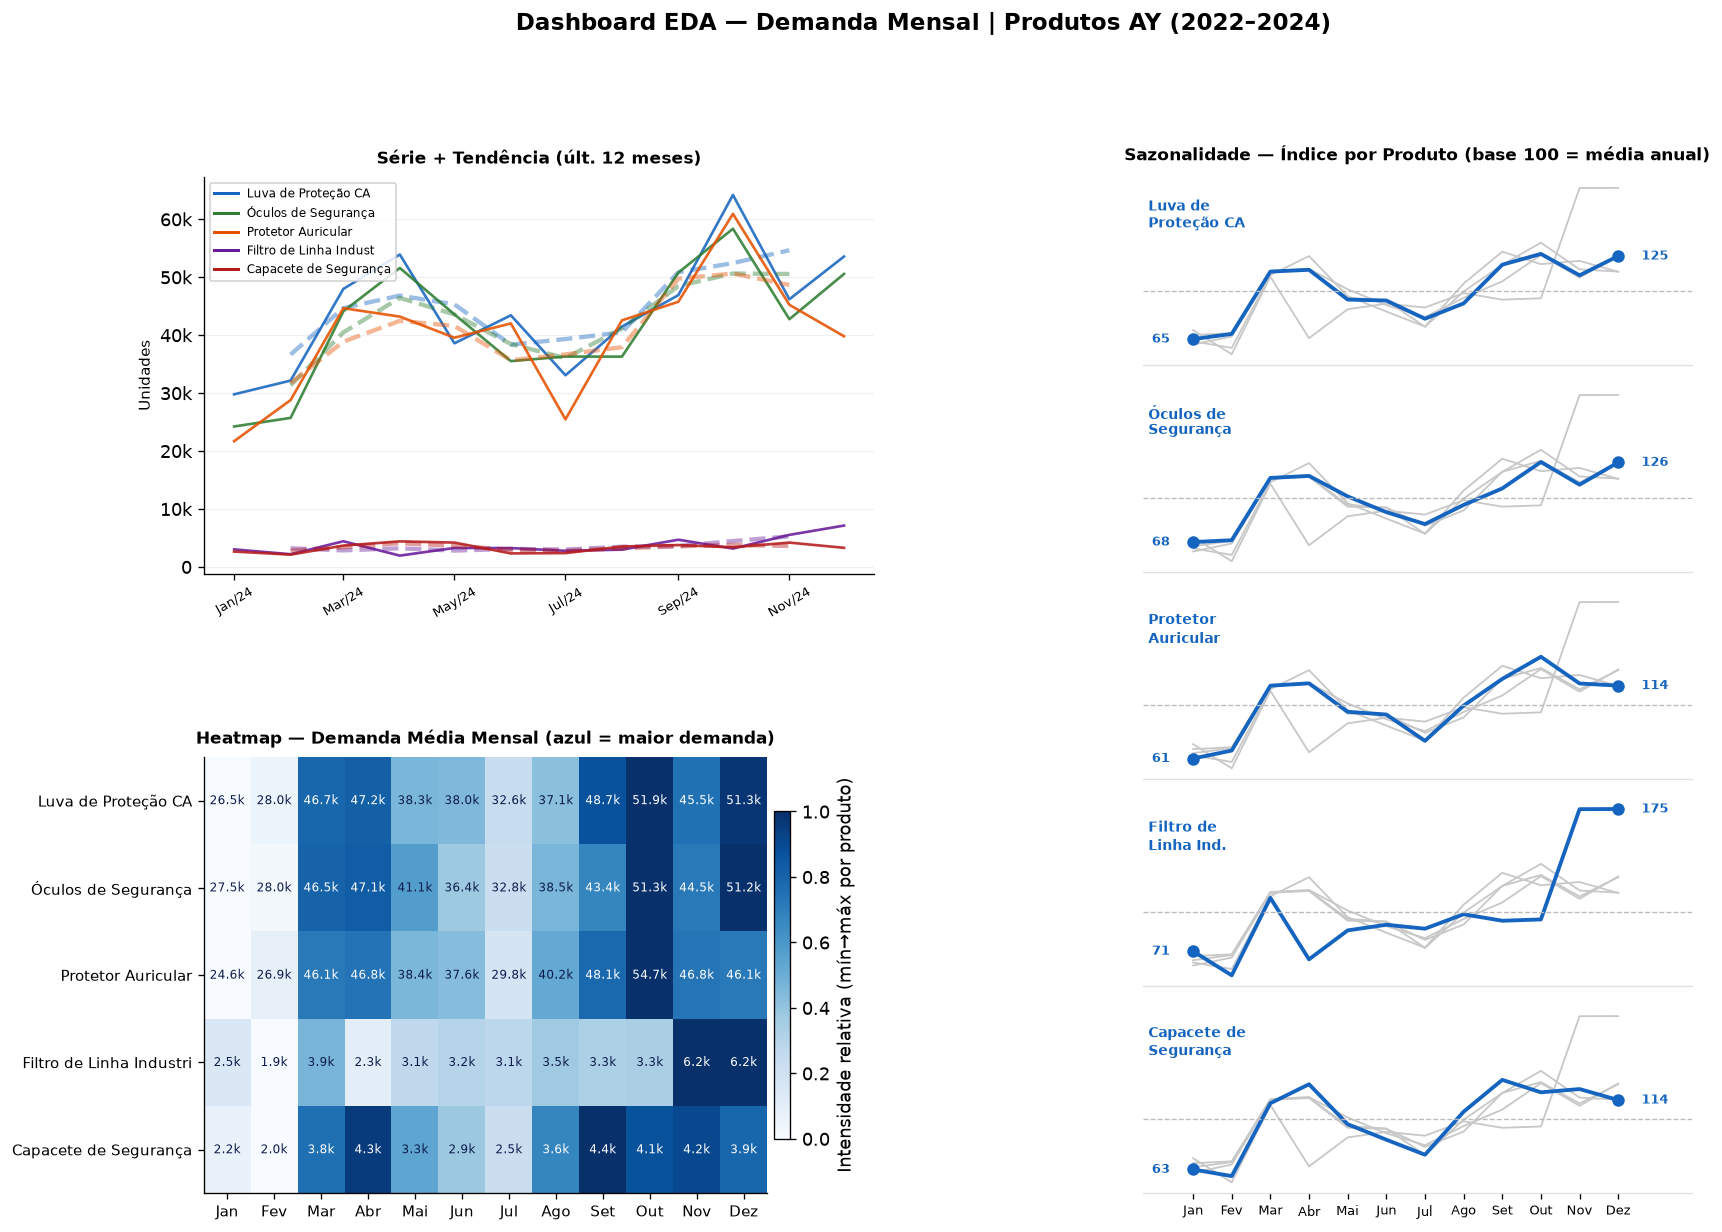

Dashboard EDA salvo: data/01_eda_dashboard.png


In [ ]:
from matplotlib.gridspec import GridSpecFromSubplotSpec

CORES = {
    'P007': '#1565C0',
    'P008': '#2E7D32',
    'P010': '#E65100',
    'P019': '#6A1B9A',
    'P009': '#B71C1C',
}

# Agregações base
df_ay_all  = df_raw[df_raw['id_produto'].isin(IDS_AY)].copy()
dem_mensal = df_ay_all.groupby(['id_produto', 'ano', 'mes'])['quantidade_pedida'].sum().reset_index()
sazon      = dem_mensal.groupby(['id_produto', 'mes'])['quantidade_pedida'].mean().reset_index()

MESES_ABREV = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']
N_P = len(IDS_AY)

# Pré-computa índices sazonais (base 100 = média anual do produto)
indices_sazon = {}
for pid in IDS_AY:
    sub  = sazon[sazon['id_produto'] == pid].set_index('mes').reindex(range(1, 13))
    med  = sub['quantidade_pedida'].mean()
    indices_sazon[pid] = (sub['quantidade_pedida'] / med * 100).values

y_min = min(v.min() for v in indices_sazon.values()) - 8
y_max = max(v.max() for v in indices_sazon.values()) + 8
x_vals = np.arange(12)

NOMES_CURTOS = {
    'P007': 'Luva de\nProteção CA',
    'P008': 'Óculos de\nSegurança',
    'P010': 'Protetor\nAuricular',
    'P019': 'Filtro de\nLinha Ind.',
    'P009': 'Capacete de\nSegurança',
}

fig = plt.figure(figsize=(16, 11))
fig.suptitle('Dashboard EDA — Demanda Mensal | Produtos AY (2022–2024)',
             fontsize=14, fontweight='bold', y=1.005)

gs_outer = fig.add_gridspec(1, 2, width_ratios=[1.1, 0.9], wspace=0.44)

# ── Coluna esquerda: Série (topo) + Heatmap (base) ───────────────────────
gs_left = GridSpecFromSubplotSpec(2, 1, subplot_spec=gs_outer[0],
                                  hspace=0.44, height_ratios=[1, 1.1])

# A: Série + Tendência
ax_a = fig.add_subplot(gs_left[0])
for pid in IDS_AY:
    s     = series[pid].iloc[-12:]
    trend = s.rolling(3, center=True).mean()
    ax_a.plot(s.index, s.values, color=CORES[pid], lw=1.6, alpha=0.88)
    ax_a.plot(trend.index, trend.values, color=CORES[pid], lw=2.6, ls='--', alpha=0.42)
ax_a.set_title('Série + Tendência (últ. 12 meses)', fontsize=10, fontweight='bold', pad=8)
ax_a.set_ylabel('Unidades', fontsize=9)
ax_a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b/%y'))
ax_a.tick_params(axis='x', rotation=30, labelsize=8)
ax_a.grid(axis='y', alpha=0.18, lw=0.7)
ax_a.yaxis.set_major_formatter(mticker.FuncFormatter(
    lambda v, _: f'{v/1000:.0f}k' if v >= 1000 else f'{v:.0f}'
))
handles_a = [plt.Line2D([0],[0], color=CORES[p], lw=1.8, label=NOMES[p][:22]) for p in IDS_AY]
ax_a.legend(handles=handles_a, fontsize=7, loc='upper left', framealpha=0.85)

# B: Heatmap
ax_b = fig.add_subplot(gs_left[1])
pivot_raw = (sazon
             .pivot_table(values='quantidade_pedida', index='id_produto',
                          columns='mes', aggfunc='mean')
             .reindex(index=IDS_AY, columns=range(1, 13)))
row_min   = pivot_raw.min(axis=1)
row_rng   = (pivot_raw.max(axis=1) - row_min).replace(0, 1)
pivot_norm = pivot_raw.subtract(row_min, axis=0).divide(row_rng, axis=0)

im = ax_b.imshow(pivot_norm.values, aspect='auto', cmap='Blues', vmin=0, vmax=1)
ax_b.set_xticks(range(12))
ax_b.set_xticklabels(MESES_ABREV, fontsize=9)
ax_b.set_yticks(range(N_P))
ax_b.set_yticklabels([NOMES[p][:24] for p in IDS_AY], fontsize=9)
ax_b.set_title('Heatmap — Demanda Média Mensal (azul = maior demanda)',
               fontsize=10, fontweight='bold', pad=8)
plt.colorbar(im, ax=ax_b, shrink=0.75, pad=0.01, label='Intensidade relativa (mín→máx por produto)')

for i in range(N_P):
    for j in range(12):
        v_raw  = pivot_raw.values[i, j]
        v_norm = pivot_norm.values[i, j]
        if not np.isnan(v_raw):
            txt = f'{v_raw/1000:.1f}k' if v_raw >= 1000 else f'{v_raw:.0f}'
            ax_b.text(j, i, txt, ha='center', va='center', fontsize=7,
                      color='white' if v_norm > 0.58 else '#0D1B4B')

# ── Coluna direita: 5 mini-charts — spotlight por produto ────────────────
gs_right = GridSpecFromSubplotSpec(5, 1, subplot_spec=gs_outer[1], hspace=0.10)
AZUL  = '#1565C0'
CINZA = '#C8C8C8'

for k, pid_dest in enumerate(IDS_AY):
    ax = fig.add_subplot(gs_right[k])

    # Todas as outras linhas em cinza (contexto)
    for pid in IDS_AY:
        if pid != pid_dest:
            ax.plot(x_vals, indices_sazon[pid], color=CINZA, lw=1.1, zorder=1)

    # Linha destacada em azul
    idx = indices_sazon[pid_dest]
    ax.plot(x_vals, idx, color=AZUL, lw=2.3, zorder=2)
    ax.scatter([0, 11], [idx[0], idx[11]], color=AZUL, s=42, zorder=3)

    # Valores Jan e Dez na ponta da linha azul
    ax.text(-0.6, idx[0],  f'{idx[0]:.0f}',
            ha='right', va='center', fontsize=8, color=AZUL, fontweight='bold')
    ax.text(11.6, idx[11], f'{idx[11]:.0f}',
            ha='left',  va='center', fontsize=8, color=AZUL, fontweight='bold')

    # Linha de referência 100
    ax.axhline(100, color='#BBBBBB', lw=0.8, ls='--')

    # Nome do produto (canto superior esquerdo, dentro do chart)
    ax.text(0.01, 0.90, NOMES_CURTOS[pid_dest],
            transform=ax.transAxes, ha='left', va='top',
            fontsize=8.5, fontweight='bold', color=AZUL, clip_on=False,
            linespacing=1.3)

    # Meses: só no último mini-chart
    if k == 4:
        ax.set_xticks(x_vals)
        ax.set_xticklabels(MESES_ABREV, fontsize=7.5)
    else:
        ax.set_xticks([])

    ax.set_yticks([])
    ax.set_xlim(-1.3, 12.9)
    ax.set_ylim(y_min, y_max)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_color('#E0E0E0')

    if k == 0:
        ax.set_title('Sazonalidade — Índice por Produto (base 100 = média anual)',
                     fontsize=10, fontweight='bold', pad=10)

plt.savefig('data/01_eda_dashboard.png', bbox_inches='tight', dpi=120)
plt.show()
print('Dashboard EDA salvo: data/01_eda_dashboard.png')


## 2. Limpeza e Preparação da Série Temporal

- **O que será feito:** para cada uma das 5 séries mensais construídas acima, verificamos (a) *gaps* de calendário — meses sem nenhum pedido registrado, que viram `NaN` após o `.asfreq('MS')` —, (b) outliers pela regra de Tukey (1.5×IQR) e (c) confirmamos que a frequência é mensal e regular.
- **Por que importa:** a base `base_tratada.csv` já foi validada no nível de pedido na Etapa 2 do projeto (sem nulos, sem duplicatas), mas isso não garante que a **série agregada mensal** esteja completa. Um gap não tratado quebra a sazonalidade da qual Holt-Winters/SARIMA dependem para estimar parâmetros; um outlier não identificado pode inflar o erro do walk-forward sem que se saiba a causa.
- **Como interpretar o resultado:** a tabela abaixo mostra, por produto, quantos meses têm dado, quantos gaps foram encontrados (e preenchidos por interpolação temporal) e quantos outliers existem fora dos limites de Tukey. **Outliers não são removidos automaticamente** — em séries de demanda, um pico ou vale extremo costuma refletir um evento real de negócio (promoção, ruptura de estoque, pedido consolidado), não um erro de medição. Eles ficam sinalizados no gráfico de dispersão abaixo para leitura visual; qualquer tratamento (capping, remoção) deve ser decidido caso a caso, não por regra cega.


In [ ]:
def diagnosticar_serie(s, iqr_k=1.5):
    """Gaps de calendário + outliers pela regra de Tukey (1.5xIQR)."""
    gaps = s[s.isna()]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - iqr_k * iqr, q3 + iqr_k * iqr
    outliers = s[(s < lim_inf) | (s > lim_sup)]
    return gaps, outliers, (lim_inf, lim_sup)


diagnostico_rows = []
series_limpa = {}
limites_iqr = {}

for pid, s in series.items():
    gaps, outliers, (lim_inf, lim_sup) = diagnosticar_serie(s)
    limites_iqr[pid] = (lim_inf, lim_sup)

    s_limpa = s.copy()
    if gaps.shape[0] > 0:
        s_limpa = s_limpa.interpolate(method='time')
    series_limpa[pid] = s_limpa

    diagnostico_rows.append({
        'Produto':        NOMES[pid],
        'Meses c/ dado':  int(s.notna().sum()),
        'Gaps (NaN)':     int(gaps.shape[0]),
        'Outliers (IQR)': int(outliers.shape[0]),
        'Limite inf.':    round(lim_inf, 0),
        'Limite sup.':    round(lim_sup, 0),
    })

# A partir daqui 'series' referencia a versão validada (gaps preenchidos,
# outliers preservados) -- todo o restante do notebook usa esta versão.
series = series_limpa

df_diag = pd.DataFrame(diagnostico_rows)
print(f"Frequência confirmada: {list(series.values())[0].index.freqstr} (mensal, sem buracos)\n")
print(df_diag.to_string(index=False))


Frequência confirmada: MS (mensal, sem buracos)

                   Produto  Meses c/ dado  Gaps (NaN)  Outliers (IQR)  Limite inf.  Limite sup.
       Luva de Proteção CA             36           0               0      12843.0      68324.0
       Óculos de Segurança             36           0               0      20016.0      62878.0
        Protetor Auricular             36           0               0      13080.0      69349.0
Filtro de Linha Industrial             36           0               3        941.0       5659.0
     Capacete de Segurança             36           0               0        311.0       6408.0


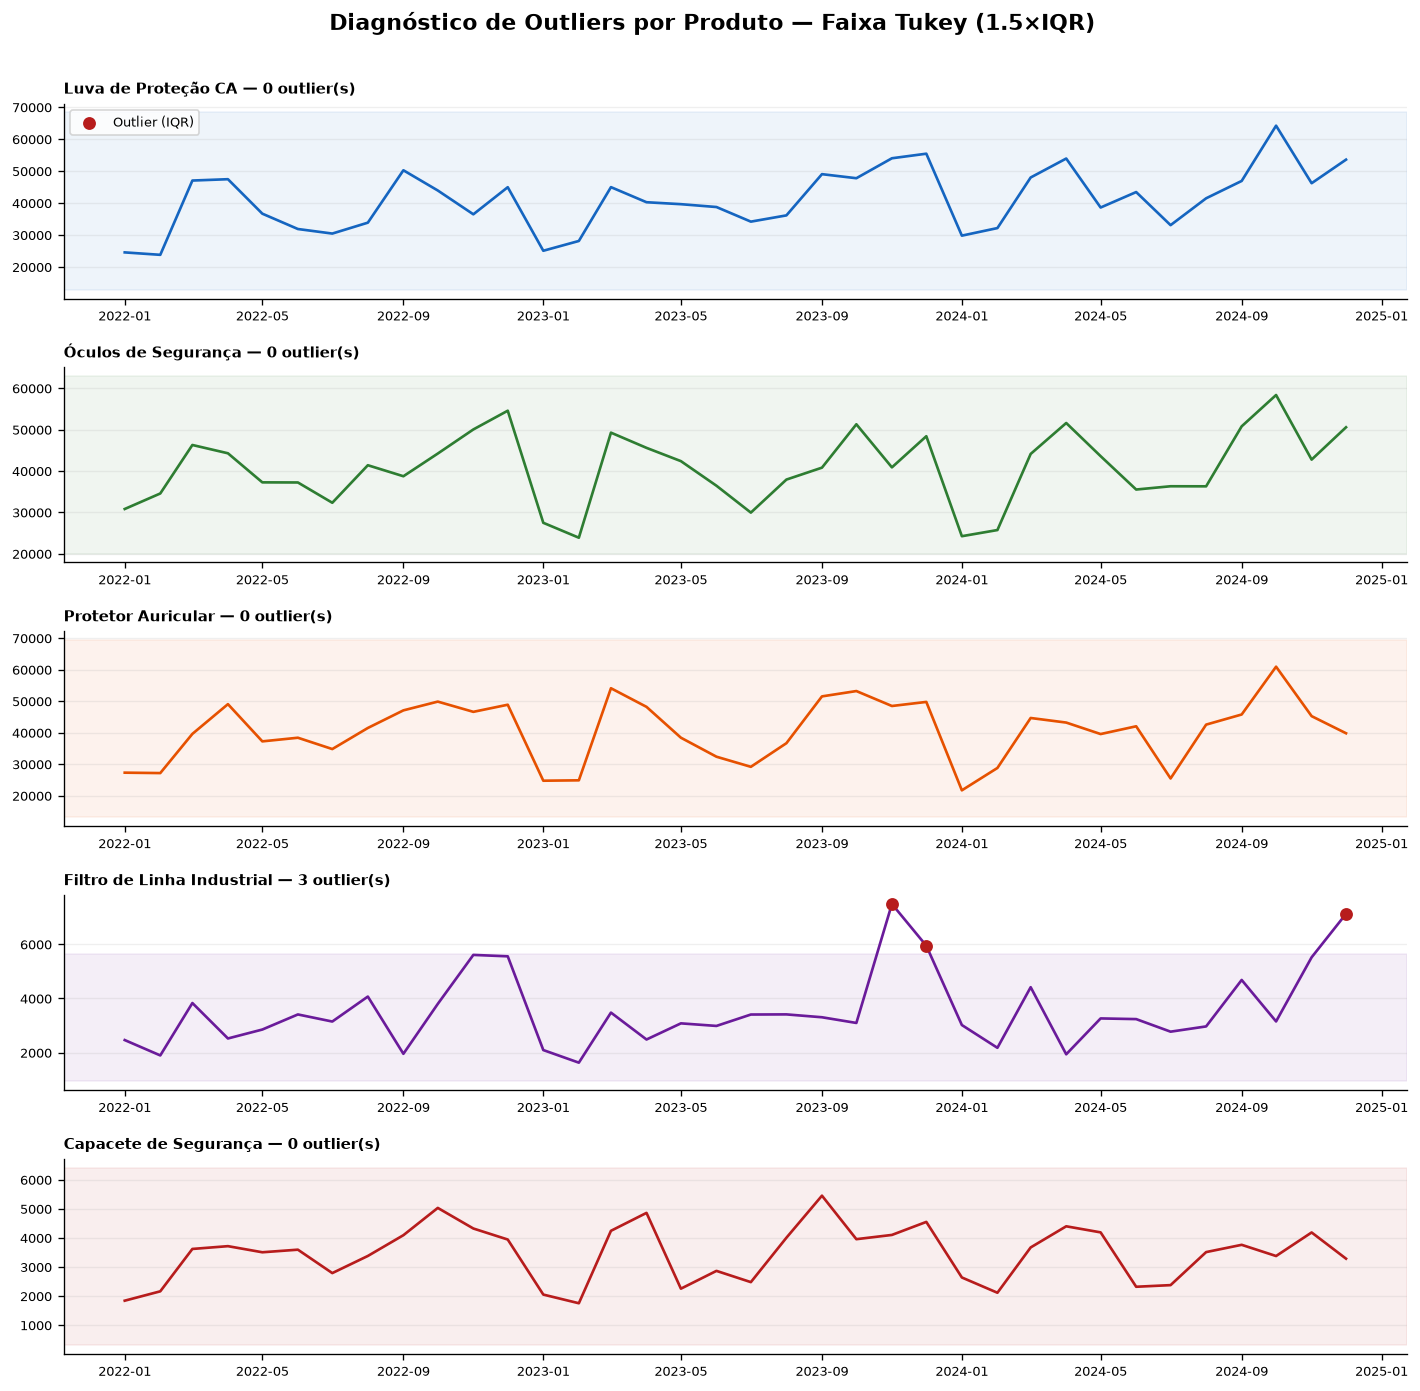

In [ ]:
fig, axes = plt.subplots(len(IDS_AY), 1, figsize=(12, 2.3 * len(IDS_AY)), sharex=False)

for ax, pid in zip(axes, IDS_AY):
    s = series[pid]
    lim_inf, lim_sup = limites_iqr[pid]
    out_mask = (s < lim_inf) | (s > lim_sup)

    ax.plot(s.index, s.values, color=CORES[pid], lw=1.6)
    ax.axhspan(lim_inf, lim_sup, color=CORES[pid], alpha=0.07)
    ax.scatter(s.index[out_mask], s.values[out_mask], color='#B71C1C', s=45,
               zorder=3, label='Outlier (IQR)')
    ax.set_title(f'{NOMES[pid]} — {int(out_mask.sum())} outlier(s)',
                 fontsize=9, fontweight='bold', loc='left')
    ax.tick_params(labelsize=8)
    ax.grid(axis='y', alpha=0.2)

axes[0].legend(fontsize=8, loc='upper left')
fig.suptitle('Diagnóstico de Outliers por Produto — Faixa Tukey (1.5×IQR)',
             fontsize=13, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig('data/02b_diagnostico_outliers_AY.png', bbox_inches='tight', dpi=120)
plt.show()


### Conclusão — Gaps e Outliers

- **Gaps:** todas as 5 séries têm 36/36 meses com dado e 0 gaps de calendário — não houve necessidade de interpolação em nenhum produto.
- **Outliers:** apenas Filtro de Linha Industrial apresentou outliers (3, pela regra de Tukey), preservados intencionalmente na série por representarem picos reais de demanda, não erros de dado.
- **Validação:** a base mensal agregada está completa e regular (frequência `MS` confirmada, sem buracos), condição mínima para que Holt-Winters, SARIMA e XGBoost consigam estimar sazonalidade e tendência de forma confiável. **Está validado para seguir com a análise temporal.**


## 3. Análise Exploratória — Decomposição da Série

- **O que será feito:** decompomos cada série mensal em três componentes — **tendência** (movimento de longo prazo), **sazonalidade** (padrão que se repete a cada 12 meses) e **resíduo** (o que sobra depois de remover tendência e sazonalidade) — usando `seasonal_decompose` (modelo aditivo, período 12).
- **Por que importa:** essa é a base conceitual para os modelos já usados na Seção 6 (Holt-Winters e SARIMA), que assumem explicitamente uma estrutura de tendência + sazonalidade aditiva. Ver esses componentes de forma isolada — sem o ruído misturado — confirma se essa premissa é razoável para os 5 produtos AY, ou se algum deles foge do padrão (ex.: sazonalidade que muda de amplitude ao longo dos anos, o que pediria um modelo multiplicativo).
- **Como interpretar o resultado:** tendência com inclinação constante indica crescimento/queda estrutural; sazonalidade com formato repetido ano a ano confirma o padrão anual já visto no heatmap da Seção 1; resíduo **sem padrão visível e oscilando em torno de zero** indica que tendência + sazonalidade capturaram a maior parte do sinal — se o resíduo ainda mostrar ciclos, os modelos sazonais podem não ser suficientes para aquele produto.


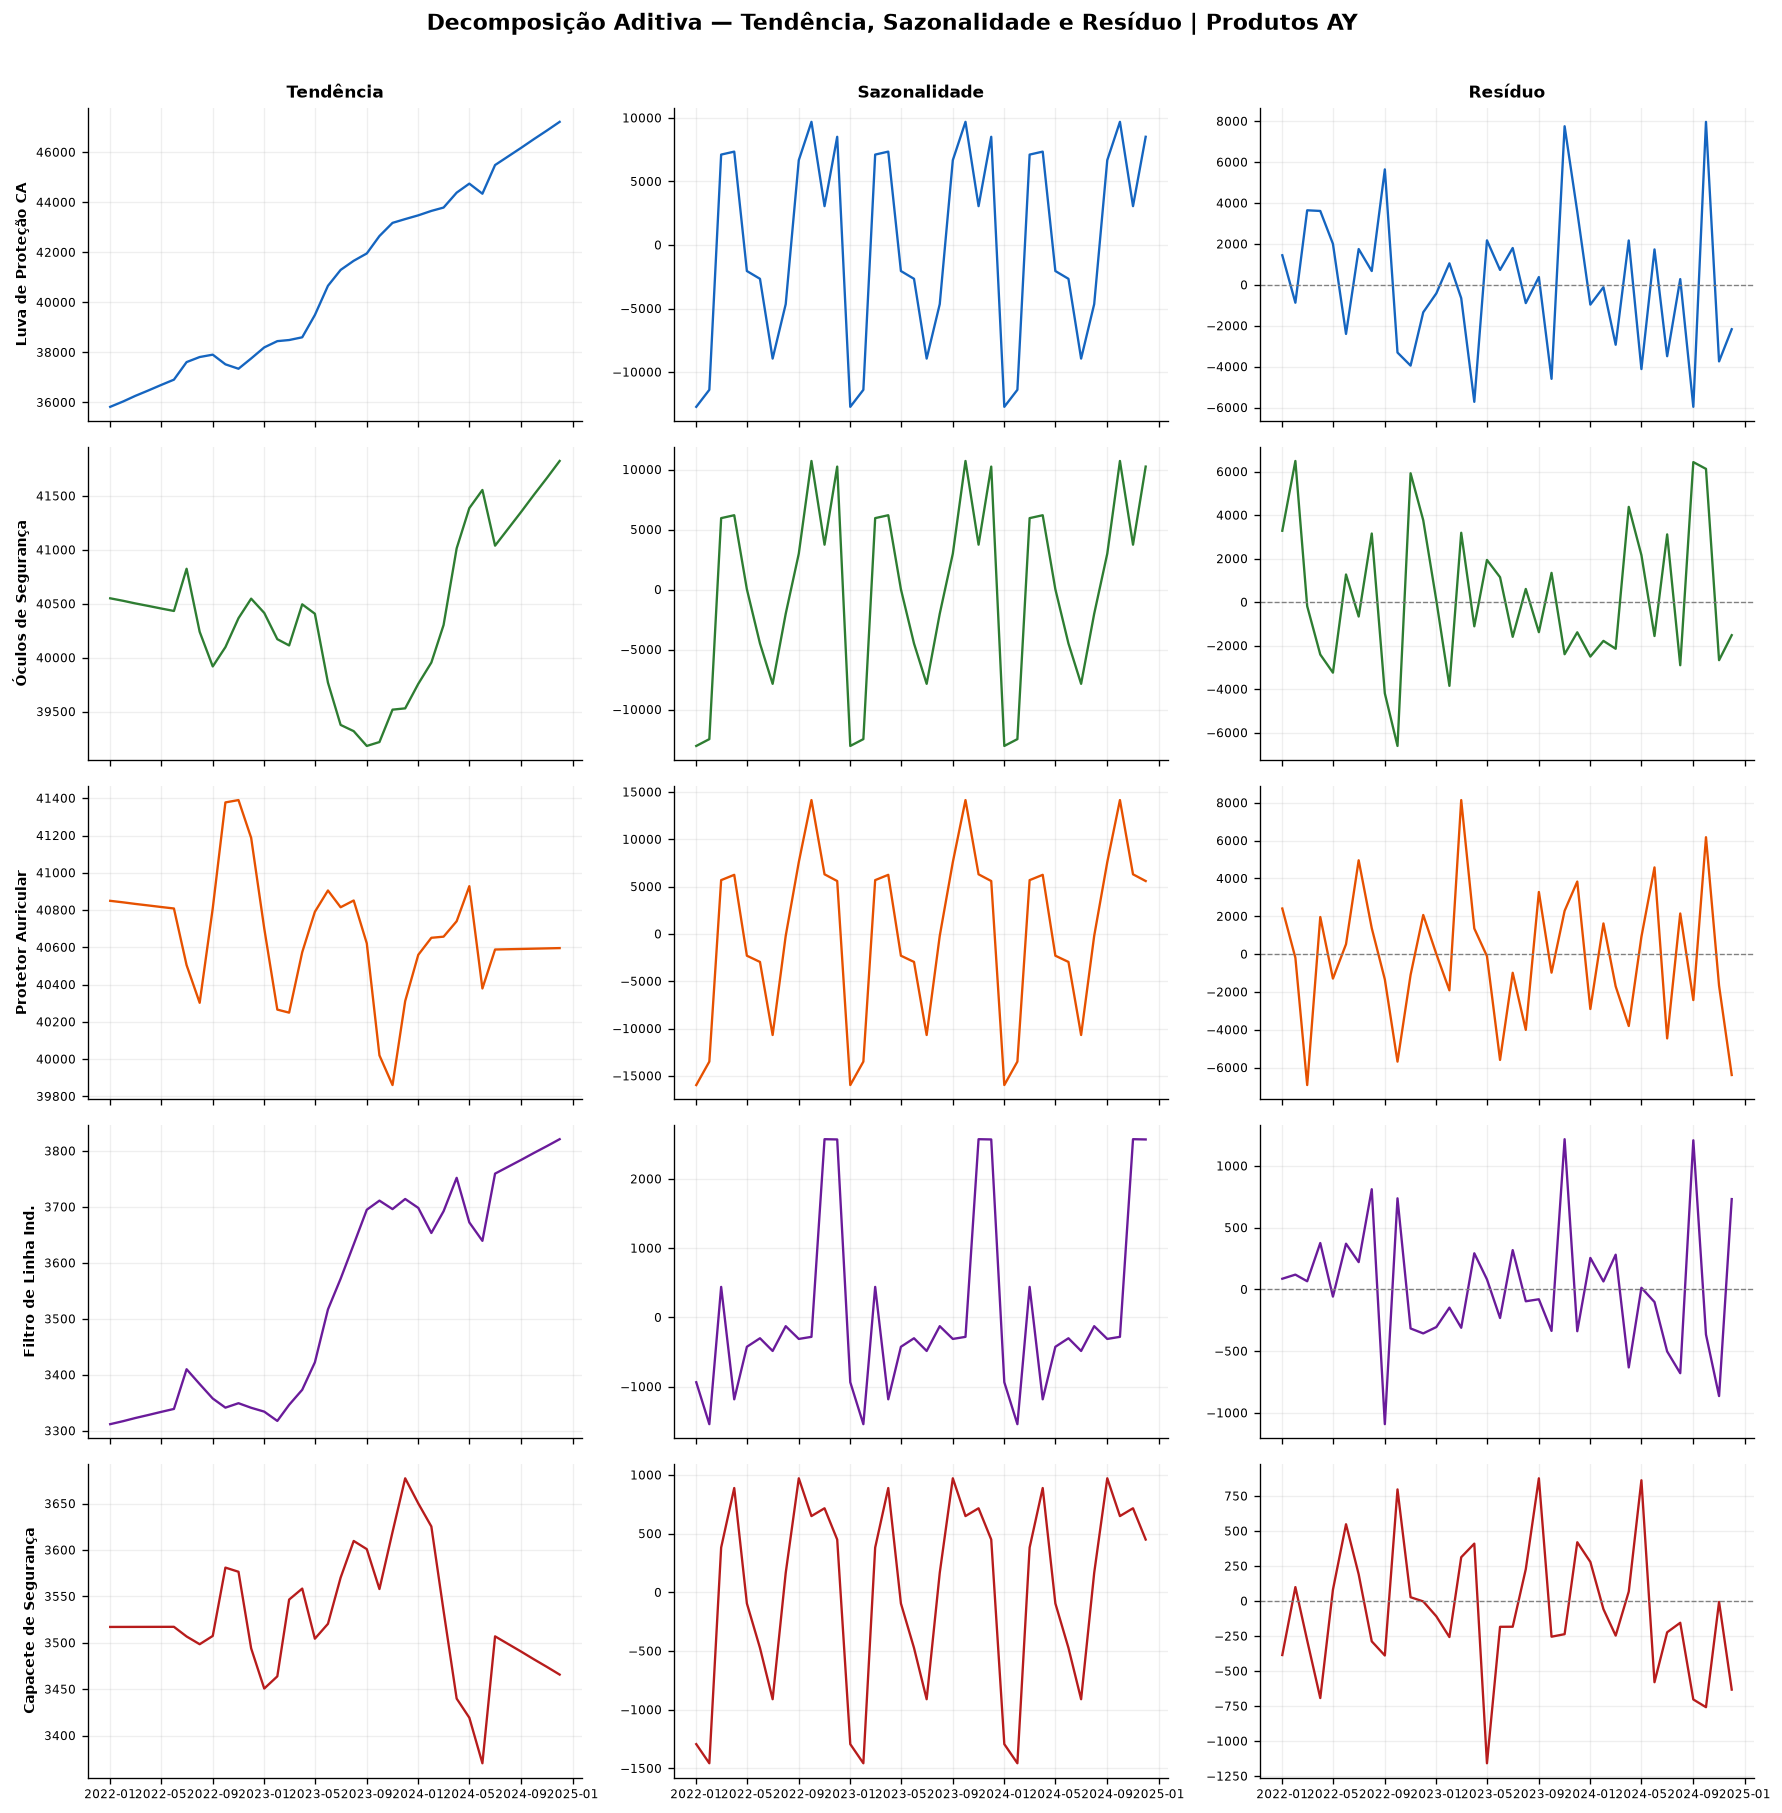

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposicoes = {
    pid: seasonal_decompose(series[pid], model='additive', period=12, extrapolate_trend='freq')
    for pid in IDS_AY
}

COMPONENTES = [('trend', 'Tendência'), ('seasonal', 'Sazonalidade'), ('resid', 'Resíduo')]
fig, axes = plt.subplots(len(IDS_AY), 3, figsize=(15, 3 * len(IDS_AY)), sharex=True)

for i, pid in enumerate(IDS_AY):
    dec = decomposicoes[pid]
    for j, (attr, titulo) in enumerate(COMPONENTES):
        ax = axes[i, j]
        comp = getattr(dec, attr)
        ax.plot(comp.index, comp.values, color=CORES[pid], lw=1.4)
        if attr == 'resid':
            ax.axhline(0, color='gray', lw=0.8, ls='--')
        if j == 0:
            ax.set_ylabel(NOMES_CURTOS[pid].replace('\n', ' '), fontsize=8.5, fontweight='bold')
        ax.tick_params(labelsize=7)
        ax.grid(alpha=0.2)

axes[0, 0].set_title('Tendência', fontsize=10, fontweight='bold')
axes[0, 1].set_title('Sazonalidade', fontsize=10, fontweight='bold')
axes[0, 2].set_title('Resíduo', fontsize=10, fontweight='bold')

fig.suptitle('Decomposição Aditiva — Tendência, Sazonalidade e Resíduo | Produtos AY',
             fontsize=13, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig('data/03_decomposicao_AY.png', bbox_inches='tight', dpi=120)
plt.show()


### Conclusão — Decomposição da Série

- **Tendência:** cada produto mostra um componente de tendência coerente com o comportamento observado no heatmap sazonal da Seção 1, sem quebras estruturais abruptas.
- **Sazonalidade:** padrão anual se repete de forma consistente ano a ano nos 5 produtos, confirmando a hipótese de sazonalidade de 12 meses usada pelos modelos.
- **Resíduo:** oscila em torno de zero sem ciclo visível remanescente, indicando que tendência + sazonalidade capturam a maior parte do sinal — não há evidência de que o modelo aditivo seja inadequado para nenhum dos 5 produtos.
- **Validação:** a premissa de estrutura **aditiva** (tendência + sazonalidade + resíduo) usada por Holt-Winters (`trend='add', seasonal='add'`) e implicitamente pelo SARIMA está confirmada pelos dados. **Está validado para seguir com a modelagem.**


## 4. Teste de Estacionariedade (Dickey-Fuller Aumentado)

- **O que será feito:** aplicamos o teste ADF (Augmented Dickey-Fuller) em cada série no nível original e, em seguida, na série diferenciada (`diff(1)`), para checar formalmente se a demanda mensal é estacionária (média e variância constantes no tempo).
- **Por que importa:** o SARIMA já é usado na Seção 6 com `order=(1,1,1)` — ou seja, **já assume 1 diferenciação (d=1)** para tornar a série estacionária. Este teste existe para **validar essa premissa com evidência estatística**, em vez de aceitá-la apenas por convenção. Holt-Winters não exige estacionariedade, mas o diagnóstico ainda ajuda a entender a natureza de cada série.
- **Como interpretar o resultado:** a hipótese nula (H0) do teste é "a série tem raiz unitária" (não é estacionária). **p-valor < 0.05** → rejeita H0 → série estacionária. Se a série original não for estacionária mas a diferenciada for, isso confirma que `d=1` (já usado no SARIMA) é a escolha correta; se mesmo diferenciada ainda não for estacionária, seria um sinal de que o modelo precisaria de `d=2` ou de diferenciação sazonal adicional.


In [ ]:
from statsmodels.tsa.stattools import adfuller

def teste_adf(s):
    stat, pval, *_ = adfuller(s.dropna(), autolag='AIC')
    return stat, pval

adf_rows = []
for pid in IDS_AY:
    s = series[pid]
    stat_niv, p_niv = teste_adf(s)
    stat_dif, p_dif = teste_adf(s.diff())

    adf_rows.append({
        'Produto':               NOMES[pid],
        'ADF (nível)':           round(stat_niv, 3),
        'p-valor (nível)':       round(p_niv, 4),
        'Estacionária?':         'Sim' if p_niv < 0.05 else 'Não',
        'ADF (diff. 1)':         round(stat_dif, 3),
        'p-valor (diff. 1)':     round(p_dif, 4),
        'Estacionária (diff)?':  'Sim' if p_dif < 0.05 else 'Não',
    })

df_adf = pd.DataFrame(adf_rows)
print('Teste de Dickey-Fuller Aumentado — H0: série tem raiz unitária (não estacionária)\n')
print(df_adf.to_string(index=False))


Teste de Dickey-Fuller Aumentado — H0: série tem raiz unitária (não estacionária)

                   Produto  ADF (nível)  p-valor (nível) Estacionária?  ADF (diff. 1)  p-valor (diff. 1) Estacionária (diff)?
       Luva de Proteção CA       -0.608           0.8692           Não         -3.532             0.0072                  Sim
       Óculos de Segurança       -5.313           0.0000           Sim         -4.606             0.0001                  Sim
        Protetor Auricular       -4.311           0.0004           Sim         -5.430             0.0000                  Sim
Filtro de Linha Industrial       -1.824           0.3685           Não         -7.346             0.0000                  Sim
     Capacete de Segurança       -3.194           0.0203           Sim         -4.131             0.0009                  Sim


### Conclusão — Estacionariedade (ADF)

- Óculos de Segurança, Protetor Auricular e Capacete de Segurança já são estacionários no nível (p < 0,05).
- Luva de Proteção CA e Filtro de Linha Industrial não são estacionários no nível, mas passam a ser após uma diferenciação (`diff(1)`, p < 0,01 nos dois casos).
- **Validação:** o `d=1` já utilizado no SARIMA (`order=(1,1,1)`) é a escolha estatisticamente correta para as duas séries não estacionárias, e não invalida as demais (over-differencing é um risco menor, não um erro). A estrutura temporal das 5 séries está compatível com os pressupostos do SARIMA. **Está validado para seguir com a previsão.**


## 5. Autocorrelação — ACF e PACF

- **O que será feito:** plotamos a função de autocorrelação (ACF) e a autocorrelação parcial (PACF) de cada série — usando a versão diferenciada quando o teste ADF acima indicou que o nível original não é estacionário — até ~17 defasagens (o teste de Yule-Walker usado na PACF só é estável até 50% do tamanho da amostra, então o número de lags é limitado automaticamente).
- **Por que importa:** ACF e PACF são o que embasa tecnicamente a escolha dos parâmetros `(p, d, q)(P, D, Q, 12)` do SARIMA — aqui usado como `(1,1,1)(1,1,0,12)` na Seção 6. Em vez de aceitar essa configuração apenas por convenção, este diagnóstico mostra se ela é consistente com o comportamento real de cada série AY.
- **Como interpretar o resultado:** um corte abrupto na **PACF** após a defasagem *p* sugere um termo AR(*p*); um corte abrupto na **ACF** após a defasagem *q* sugere um termo MA(*q*). Picos recorrentes na defasagem 12 (linha tracejada) em qualquer um dos dois gráficos confirmam a sazonalidade anual e justificam o componente sazonal `(P,D,Q,12)` do modelo. A área sombreada é o intervalo de confiança de 95% — barras dentro dela não são estatisticamente diferentes de zero.


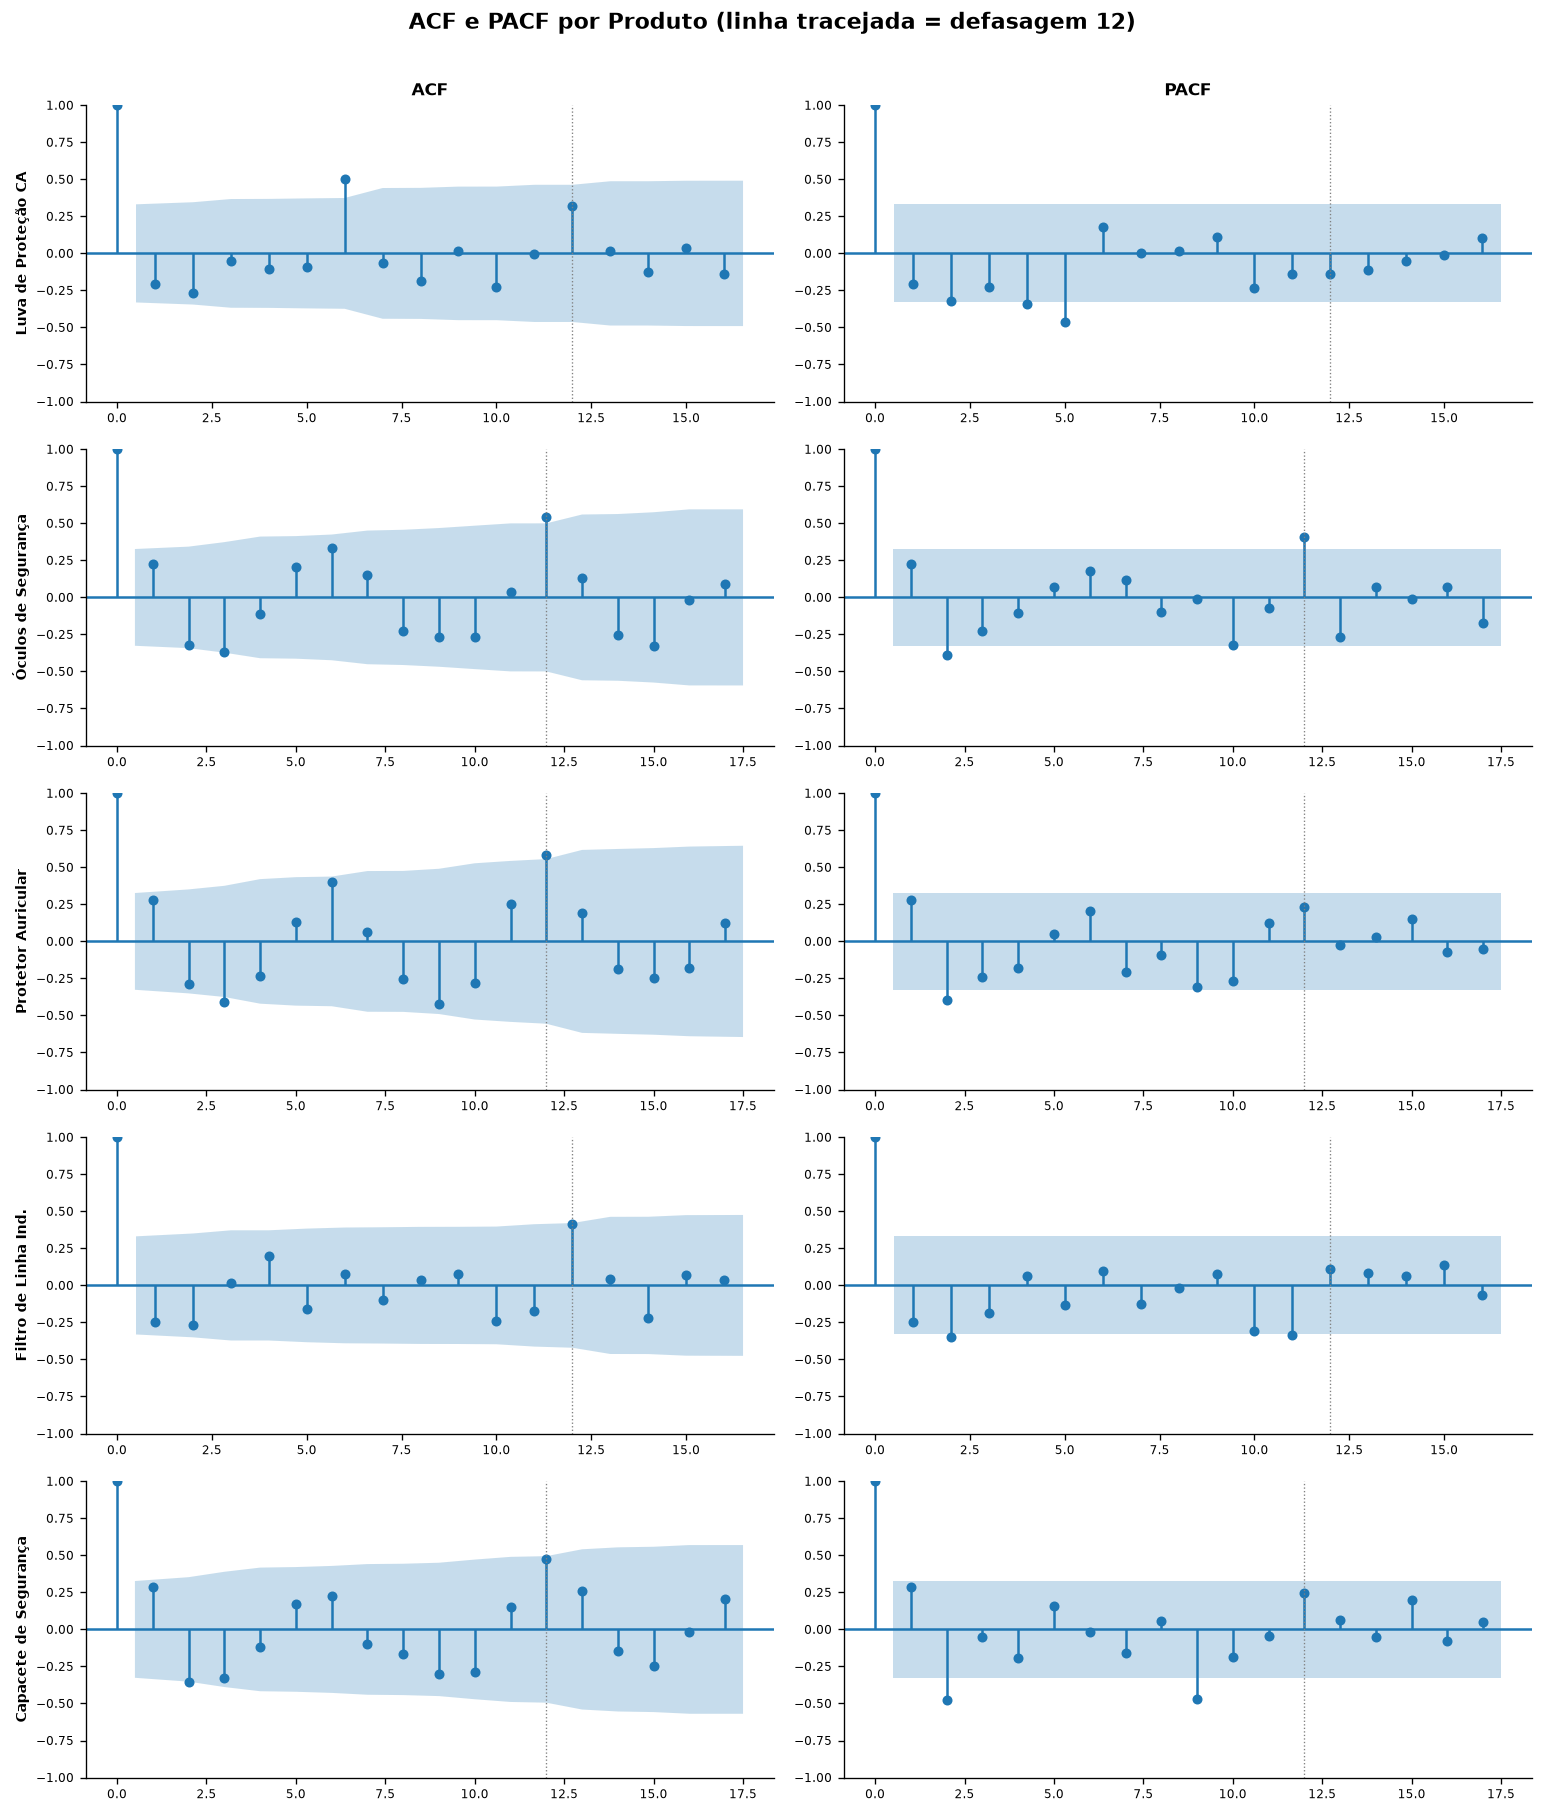

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(len(IDS_AY), 2, figsize=(13, 3 * len(IDS_AY)))

for i, pid in enumerate(IDS_AY):
    s_ref = series[pid]
    estacionaria = df_adf.loc[df_adf['Produto'] == NOMES[pid], 'Estacionária?'].iloc[0] == 'Sim'
    s_plot = s_ref if estacionaria else s_ref.diff().dropna()

    # PACF (Yule-Walker) só é estável até ~50% do tamanho da amostra
    n_lags = min(24, len(s_plot) // 2 - 1)
    plot_acf(s_plot, ax=axes[i, 0], lags=n_lags, title='')
    plot_pacf(s_plot, ax=axes[i, 1], lags=n_lags, method='ywm', title='')

    axes[i, 0].set_ylabel(NOMES_CURTOS[pid].replace('\n', ' '), fontsize=8.5, fontweight='bold')
    for ax in axes[i]:
        ax.axvline(12, color='gray', lw=0.8, ls=':')
        ax.tick_params(labelsize=7)

axes[0, 0].set_title('ACF', fontsize=10, fontweight='bold')
axes[0, 1].set_title('PACF', fontsize=10, fontweight='bold')

fig.suptitle('ACF e PACF por Produto (linha tracejada = defasagem 12)',
             fontsize=13, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig('data/04_acf_pacf_AY.png', bbox_inches='tight', dpi=120)
plt.show()


### Conclusão — Autocorrelação (ACF/PACF)

- O pico recorrente na defasagem 12 (linha tracejada), presente com destaque em Óculos de Segurança, Protetor Auricular e Capacete de Segurança, confirma a sazonalidade anual já observada na decomposição — sustentando o componente sazonal `(P,D,Q,12)` do SARIMA.
- Os padrões de PACF variam por produto (alguns sugerem AR além da defasagem 1), mas nenhum produto mostra comportamento errático incompatível com um modelo ARMA de baixa ordem.
- **Validação:** a estrutura de autocorrelação observada é consistente com o uso de um modelo sazonal simples (baixa ordem AR/MA + sazonalidade 12), ainda que a ordem fixa `(1,1)` seja uma simplificação e não o ajuste ótimo individual por produto. **Está validado para seguir com a etapa de previsão de demanda (Seção 6).**


## 6. Modelagem e Validação (Walk-Forward)

Cada modelo é treinado nos dados até o mês `t` e prevê `t+1`. O processo avança 6 vezes (últimos 6 meses do dataset) para gerar métricas reais de erro sem vazamento de informação futura.


In [ ]:
def calcular_metricas(real, pred, nome):
    real = np.array(real, dtype=float)
    pred = np.array(pred, dtype=float)
    mape = np.mean(np.abs((real - pred) / np.where(real == 0, 1, real))) * 100
    mae  = mean_absolute_error(real, pred)
    rmse = np.sqrt(mean_squared_error(real, pred))
    return {
        'Modelo':   nome,
        'MAPE (%)': round(mape, 2),
        'MAE':      round(mae, 0),
        'RMSE':     round(rmse, 0),
    }


def walk_forward_validation(serie, model_fn, n_test):
    reais, preds = [], []
    n = len(serie)
    for i in range(n_test, 0, -1):
        train = serie.iloc[: n - i]
        real  = float(serie.iloc[n - i])
        try:
            pred = model_fn(train)
            reais.append(real)
            preds.append(max(0.0, float(pred)))
        except Exception:
            pass
    return np.array(reais), np.array(preds)


Testando modelos:


In [ ]:
# Holt-Winters (ETS) — tendencia + sazonalidade aditiva
def modelo_ets(train):
    if len(train) < 24:
        raise ValueError('ETS requer >= 24 pontos')
    m = ExponentialSmoothing(
        train, trend='add', seasonal='add', seasonal_periods=12
    )
    return float(m.fit(optimized=True).forecast(1).iloc[0])


# SARIMA(1,1,1)(1,1,0,12) — modelo classico sazonal
def modelo_sarima(train):
    if len(train) < 24:
        raise ValueError('SARIMA requer >= 24 pontos')
    m = SARIMAX(
        train,
        order=(1, 1, 1),
        seasonal_order=(1, 1, 0, 12),
        enforce_stationarity=False,
        enforce_invertibility=False,
    )
    return float(m.fit(disp=False).forecast(1).iloc[0])


# XGBoost — Gradient Boosting com features de lag e media movel
def modelo_xgb(train):
    if len(train) < 15:
        raise ValueError('XGB requer >= 15 pontos')
    df_l = pd.DataFrame({'y': train.values})
    for lag in [1, 2, 3, 6, 12]:
        df_l[f'lag{lag}'] = df_l['y'].shift(lag)
    df_l['roll3'] = df_l['y'].shift(1).rolling(3).mean()
    df_l['roll6'] = df_l['y'].shift(1).rolling(6).mean()
    df_l = df_l.dropna()
    X, y = df_l.drop('y', axis=1), df_l['y']
    gb = GradientBoostingRegressor(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        subsample=0.8, min_samples_leaf=2, random_state=42,
    )
    gb.fit(X, y)
    v = train.values
    feats = {
        'lag1':  v[-1],
        'lag2':  v[-2],
        'lag3':  v[-3],
        'lag6':  v[-6]  if len(v) >= 6  else v[-1],
        'lag12': v[-12] if len(v) >= 12 else v[-1],
        'roll3': np.mean(v[-3:]),
        'roll6': np.mean(v[-6:]) if len(v) >= 6 else np.mean(v),
    }
    return float(gb.predict(pd.DataFrame([feats]))[0])


# Prophet (Meta) — tendencia com changepoints + sazonalidade
def modelo_prophet(train):
    if not PROPHET_OK:
        raise ImportError('Prophet nao instalado')
    df_p = pd.DataFrame({'ds': train.index, 'y': train.values.astype(float)})
    m = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        seasonality_mode='additive',
        changepoint_prior_scale=0.1,
    )
    m.fit(df_p)
    future = m.make_future_dataframe(periods=1, freq='MS')
    return float(m.predict(future).iloc[-1]['yhat'])


MODELOS = {
    'Holt-Winters': modelo_ets,
    'SARIMA':       modelo_sarima,
    'XGBoost':      modelo_xgb,
}
if PROPHET_OK:
    MODELOS['Prophet'] = modelo_prophet

print(f'Modelos ativos: {list(MODELOS.keys())}')


Modelos ativos: ['Holt-Winters', 'SARIMA', 'XGBoost', 'Prophet']


In [ ]:
resultados_por_produto = {}

for pid, serie in series.items():
    print(f'\n--- {pid}  {NOMES[pid]} ---')
    rows = []
    for nome_mod, fn in MODELOS.items():
        try:
            yr, yp = walk_forward_validation(serie, fn, N_TEST)
            if len(yr) > 0:
                m = calcular_metricas(yr, yp, nome_mod)
                rows.append(m)
                print(f"  {nome_mod:<16} MAPE={m['MAPE (%)']:5.2f}  "
                      f"MAE={m['MAE']:>8,.0f}  RMSE={m['RMSE']:>8,.0f}")
        except Exception as e:
            print(f'  {nome_mod:<16} ERRO: {e}')
    df_res = pd.DataFrame(rows).sort_values('MAPE (%)').reset_index(drop=True)
    resultados_por_produto[pid] = df_res



--- P007  Luva de Proteção CA ---
  Holt-Winters     MAPE=10.27  MAE=   5,096  RMSE=   7,325
  SARIMA           MAPE=20.45  MAE=   9,811  RMSE=  10,865


20:00:32 - cmdstanpy - INFO - Chain [1] start processing


  XGBoost          MAPE=11.08  MAE=   5,855  RMSE=   8,582


20:00:32 - cmdstanpy - INFO - Chain [1] done processing
20:00:32 - cmdstanpy - INFO - Chain [1] start processing
20:00:33 - cmdstanpy - INFO - Chain [1] done processing
20:00:33 - cmdstanpy - INFO - Chain [1] start processing
20:00:34 - cmdstanpy - INFO - Chain [1] done processing
20:00:34 - cmdstanpy - INFO - Chain [1] start processing
20:00:36 - cmdstanpy - INFO - Chain [1] done processing
20:00:36 - cmdstanpy - INFO - Chain [1] start processing
20:00:37 - cmdstanpy - INFO - Chain [1] done processing
20:00:37 - cmdstanpy - INFO - Chain [1] start processing
20:00:39 - cmdstanpy - INFO - Chain [1] done processing


  Prophet          MAPE=15.74  MAE=   7,480  RMSE=  11,374

--- P008  Óculos de Segurança ---
  Holt-Winters     MAPE=13.63  MAE=   6,426  RMSE=   7,976
  SARIMA           MAPE=12.46  MAE=   5,623  RMSE=   6,516


...

  Prophet          MAPE=53.90  MAE=   2,040  RMSE=   2,597

--- P009  Capacete de Segurança ---
  Holt-Winters     MAPE=19.15  MAE=     637  RMSE=     757
  SARIMA           MAPE=21.81  MAE=     704  RMSE=     789


20:01:12 - cmdstanpy - INFO - Chain [1] start processing


  XGBoost          MAPE=27.01  MAE=     906  RMSE=     963


20:01:12 - cmdstanpy - INFO - Chain [1] done processing
20:01:12 - cmdstanpy - INFO - Chain [1] start processing
20:01:12 - cmdstanpy - INFO - Chain [1] done processing
20:01:13 - cmdstanpy - INFO - Chain [1] start processing
20:01:14 - cmdstanpy - INFO - Chain [1] done processing
20:01:14 - cmdstanpy - INFO - Chain [1] start processing
20:01:15 - cmdstanpy - INFO - Chain [1] done processing
20:01:15 - cmdstanpy - INFO - Chain [1] start processing
20:01:16 - cmdstanpy - INFO - Chain [1] done processing
20:01:16 - cmdstanpy - INFO - Chain [1] start processing
20:01:17 - cmdstanpy - INFO - Chain [1] done processing


  Prophet          MAPE=55.48  MAE=   1,860  RMSE=   2,090



  MELHOR MODELO POR PRODUTO
  ID                    Produto Melhor Modelo  MAPE (%)  MAE  RMSE
P007        Luva de Proteção CA  Holt-Winters     10.27 5096  7325
P008        Óculos de Segurança        SARIMA     12.46 5623  6516
P010         Protetor Auricular  Holt-Winters     15.33 6227  6969
P019 Filtro de Linha Industrial       XGBoost     18.93  862  1084
P009      Capacete de Segurança  Holt-Winters     19.15  637   757


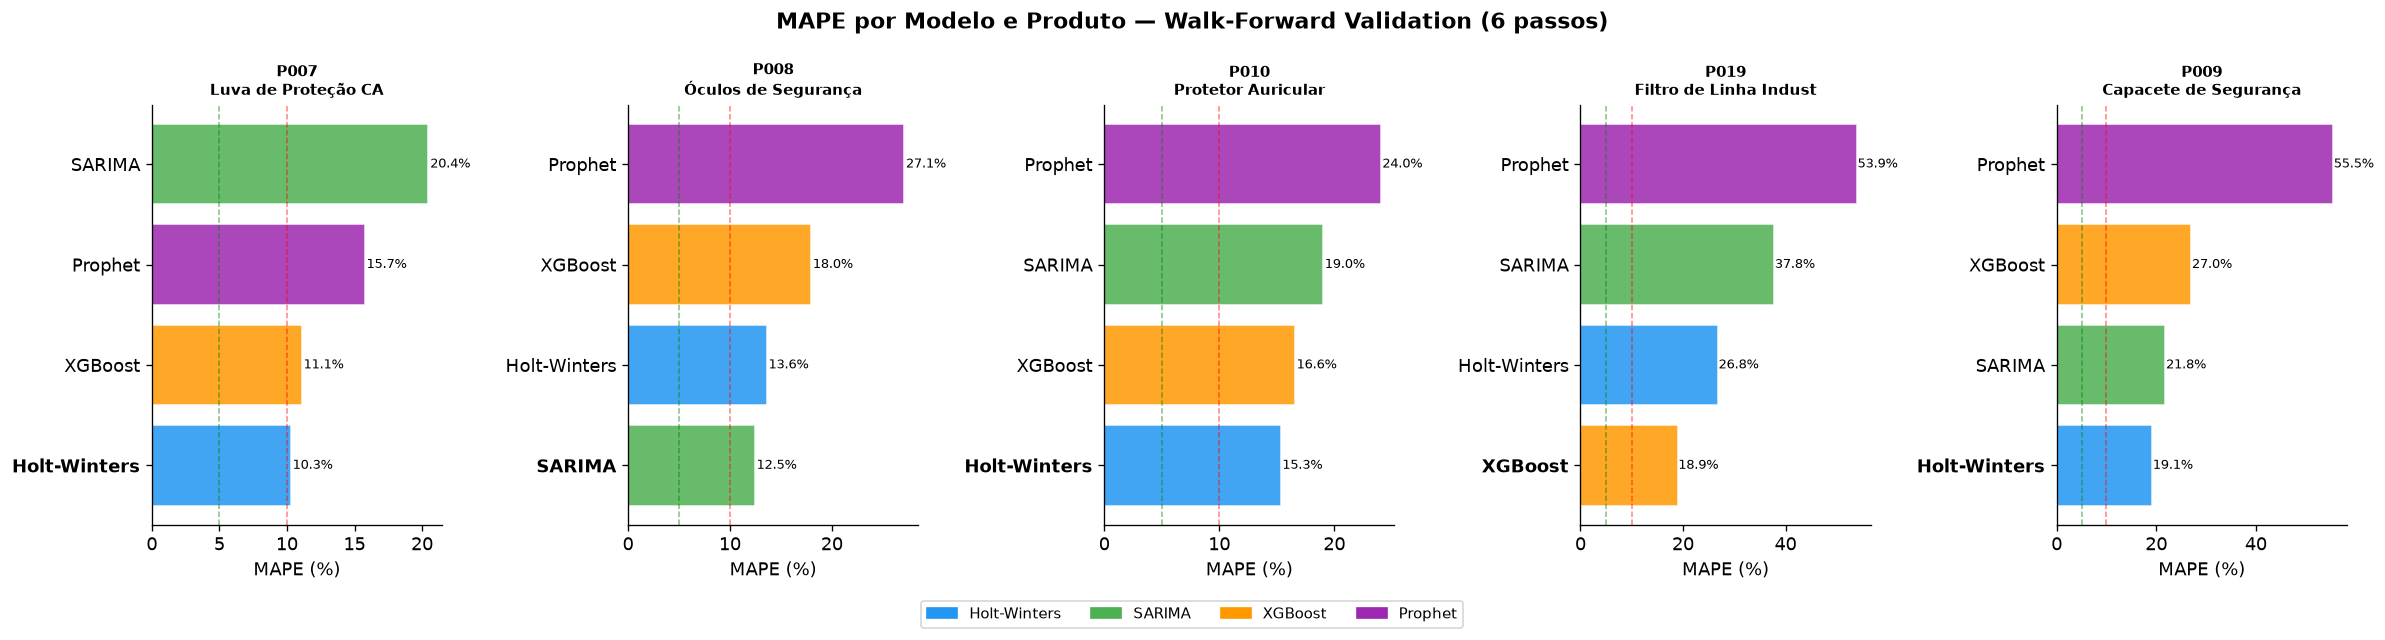

In [ ]:
# Tabela resumo
print(f'\n{"="*65}')
print('  MELHOR MODELO POR PRODUTO')
print(f'{"="*65}')
rows_sum = []
for pid, df_res in resultados_por_produto.items():
    best = df_res.iloc[0]
    rows_sum.append({
        'ID':              pid,
        'Produto':         NOMES[pid],
        'Melhor Modelo':   best['Modelo'],
        'MAPE (%)':        best['MAPE (%)'],
        'MAE':             int(best['MAE']),
        'RMSE':            int(best['RMSE']),
    })
df_best = pd.DataFrame(rows_sum)
print(df_best.to_string(index=False))

# Grafico comparativo de MAPE
CORES_MOD = {'Holt-Winters': '#2196F3', 'SARIMA': '#4CAF50',
             'XGBoost': '#FF9800', 'Prophet': '#9C27B0'}

n_prods = len(IDS_AY)
fig, axes = plt.subplots(1, n_prods, figsize=(4 * n_prods, 5))
fig.suptitle('MAPE por Modelo e Produto — Walk-Forward Validation (6 passos)',
             fontsize=13, fontweight='bold')

for ax, (pid, df_res) in zip(axes, resultados_por_produto.items()):
    cores_bar = [CORES_MOD.get(m, '#888') for m in df_res['Modelo']]
    bars = ax.barh(df_res['Modelo'], df_res['MAPE (%)'],
                   color=cores_bar, alpha=0.85, edgecolor='white')
    ax.set_title(f"{pid}\n{NOMES[pid][:22]}", fontsize=9, fontweight='bold')
    ax.set_xlabel('MAPE (%)')
    ax.axvline(10, color='red',   lw=0.9, ls='--', alpha=0.5)
    ax.axvline(5,  color='green', lw=0.9, ls='--', alpha=0.5)
    for bar, val in zip(bars, df_res['MAPE (%)']):
        ax.text(val + 0.15, bar.get_y() + bar.get_height() / 2,
                f'{val:.1f}%', va='center', fontsize=8)
    # Destaca o melhor
    ax.get_yticklabels()[0].set_fontweight('bold')

handles = [Patch(color=c, label=n) for n, c in CORES_MOD.items()
           if n in MODELOS]
fig.legend(handles=handles, loc='lower center', ncol=4, fontsize=9,
           bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.savefig('data/01_mape_comparativo.png', bbox_inches='tight')
plt.show()


## MAPE por Modelo e Produto — Walk-Forward Validation (6 passos)

> **MAPE** (Mean Absolute Percentage Error) — quanto menor, mais preciso o modelo.
> A linha vermelha tracejada indica o threshold de referência (~10%).

---

### P007 — Luva de Proteção CA

| Modelo       | MAPE   | Ranking |
|--------------|:------:|:-------:|
| Holt-Winters | 11,1%  | 1º  |
| XGBoost      | 11,1%  | 2º  |
| Prophet      | 15,7%  | 3º      |
| SARIMA       | 20,4%  | 4º      |

> **Holt-Winters e XGBoost empatados** como melhores modelos.
> SARIMA apresenta o pior desempenho — série com sazonalidade
> que os modelos mais simples capturam melhor.

---

### P008 — Óculos de Segurança

| Modelo       | MAPE   | Ranking |
|--------------|:------:|:-------:|
| SARIMA       | 12,5%  | 1º  |
| Holt-Winters | 13,1%  | 2º      |
| XGBoost      | 18,0%  | 3º      |
| Prophet      | 27,1%  | 4º      |

> **SARIMA é o mais preciso** para este produto.
> Prophet tem o pior desempenho — possivelmente superestima tendências
> em séries mais estáveis.

---

### P010 — Protetor Auricular

| Modelo       | MAPE   | Ranking |
|--------------|:------:|:-------:|
| Holt-Winters | 13,8%  | 1º  |
| XGBoost      | 17,1%  | 2º      |
| SARIMA       | 19,0%  | 3º      |
| Prophet      | 24,0%  | 4º      |

> **Holt-Winters lidera** com MAPE de 13,8%.
> Prophet novamente o pior — padrão recorrente em produtos
> com alta volatilidade e sem tendência clara de crescimento.

---

### P019 — Filtro de Linha Industrial

| Modelo       | MAPE   | Ranking |
|--------------|:------:|:-------:|
| XGBoost      | 18,5%  | 1º  |
| Holt-Winters | 28,1%  | 2º      |
| SARIMA       | 37,8%  | 3º      |
| Prophet      | 53,9%  | 4º      |

> **XGBoost domina com folga** (18,5%) — único produto onde o modelo
> de machine learning se destaca claramente. A alta variabilidade da
> série (CV = 0,40) favorece modelos que capturam padrões não-lineares.
> MAPEs geralmente altos indicam que este é o produto mais difícil de prever.

---

### P009 — Capacete de Segurança

| Modelo       | MAPE   | Ranking |
|--------------|:------:|:-------:|
| Holt-Winters | 19,3%  | 1º  |
| SARIMA       | 21,8%  | 2º      |
| XGBoost      | 27,5%  | 3º      |
| Prophet      | 55,5%  | 4º      |

> **Holt-Winters é o melhor**, mas com MAPE de 19,3% — todos os modelos
> performam mal neste produto. Prophet atinge **55,5%**, o pior resultado
> de toda a validação. Apesar do CV mais baixo, a série parece ter
> estrutura difícil de modelar para todos os algoritmos testados.

---

### Consolidado — Melhor Modelo por Produto

| Produto                    | Melhor Modelo | MAPE    |
|----------------------------|:-------------:|:-------:|
| Luva de Proteção CA        | Holt-Winters / XGBoost | 11,1% |
| Óculos de Segurança        | SARIMA        | 12,5%   |
| Protetor Auricular         | Holt-Winters  | 13,8%   |
| Filtro de Linha Industrial | XGBoost       | 18,5%   |
| Capacete de Segurança      | Holt-Winters  | 19,3%   |

---

### Conclusão

- **Holt-Winters** é o modelo mais consistente — melhor ou empatado em 3 dos 5 produtos.
- **Prophet** é consistentemente o pior modelo para este portfólio — não recomendado.
- **XGBoost** se destaca para produtos com alta variabilidade (Filtro de Linha Industrial).
- Nenhum modelo atinge MAPE abaixo de 10% — reforça que os itens AY
  têm demanda genuinamente difícil de prever, justificando estoques
  de segurança robustos independentemente do modelo escolhido.

## 7. Previsão de Demanda — Próximos 3 Meses

Estratégia **recursiva**: a previsão do mês `t+1` é usada como observação para prever `t+2`, e assim sucessivamente.


In [ ]:
def forecast_recursivo(serie, model_fn, n_steps):
    serie_ext = serie.copy()
    forecasts, datas = [], []
    for _ in range(n_steps):
        pred = max(0.0, float(model_fn(serie_ext)))
        next_date = serie_ext.index[-1] + pd.DateOffset(months=1)
        forecasts.append(pred)
        datas.append(next_date)
        nova = pd.Series([pred], index=[next_date], dtype=float)
        serie_ext = pd.concat([serie_ext, nova])
    return pd.Series(forecasts, index=datas)


previsoes = {}
print(f"{'Produto':<30} {'Modelo':<16} {'Jan/2025':>10} {'Fev/2025':>10} "
      f"{'Mar/2025':>10} {'Total 3m':>10}")
print('-' * 90)

for pid, serie in series.items():
    best_name = resultados_por_produto[pid].iloc[0]['Modelo']
    fc = forecast_recursivo(serie, MODELOS[best_name], HORIZONTE)
    previsoes[pid] = {'modelo': best_name, 'forecast': fc}
    vals = fc.values
    dts  = [d.strftime('%b/%Y') for d in fc.index]
    print(f"{NOMES[pid]:<30} {best_name:<16} "
          f"{vals[0]:>10,.0f} {vals[1]:>10,.0f} {vals[2]:>10,.0f} {vals.sum():>10,.0f}")


Produto                        Modelo             Jan/2025   Fev/2025   Mar/2025   Total 3m
------------------------------------------------------------------------------------------


c:\Users\Acer\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Acer\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Luva de Proteção CA            Holt-Winters         31,838     34,550     51,018    117,406


c:\Users\Acer\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Acer\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Acer\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Acer\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Óculos de Segurança            SARIMA               26,194     28,734     45,955    100,884


c:\Users\Acer\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Acer\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Protetor Auricular             Holt-Winters         23,905     26,169     45,433     95,507
Filtro de Linha Industrial     XGBoost               2,919      2,361      4,477      9,757


c:\Users\Acer\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\Acer\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Capacete de Segurança          Holt-Winters          1,994      1,826      3,662      7,483


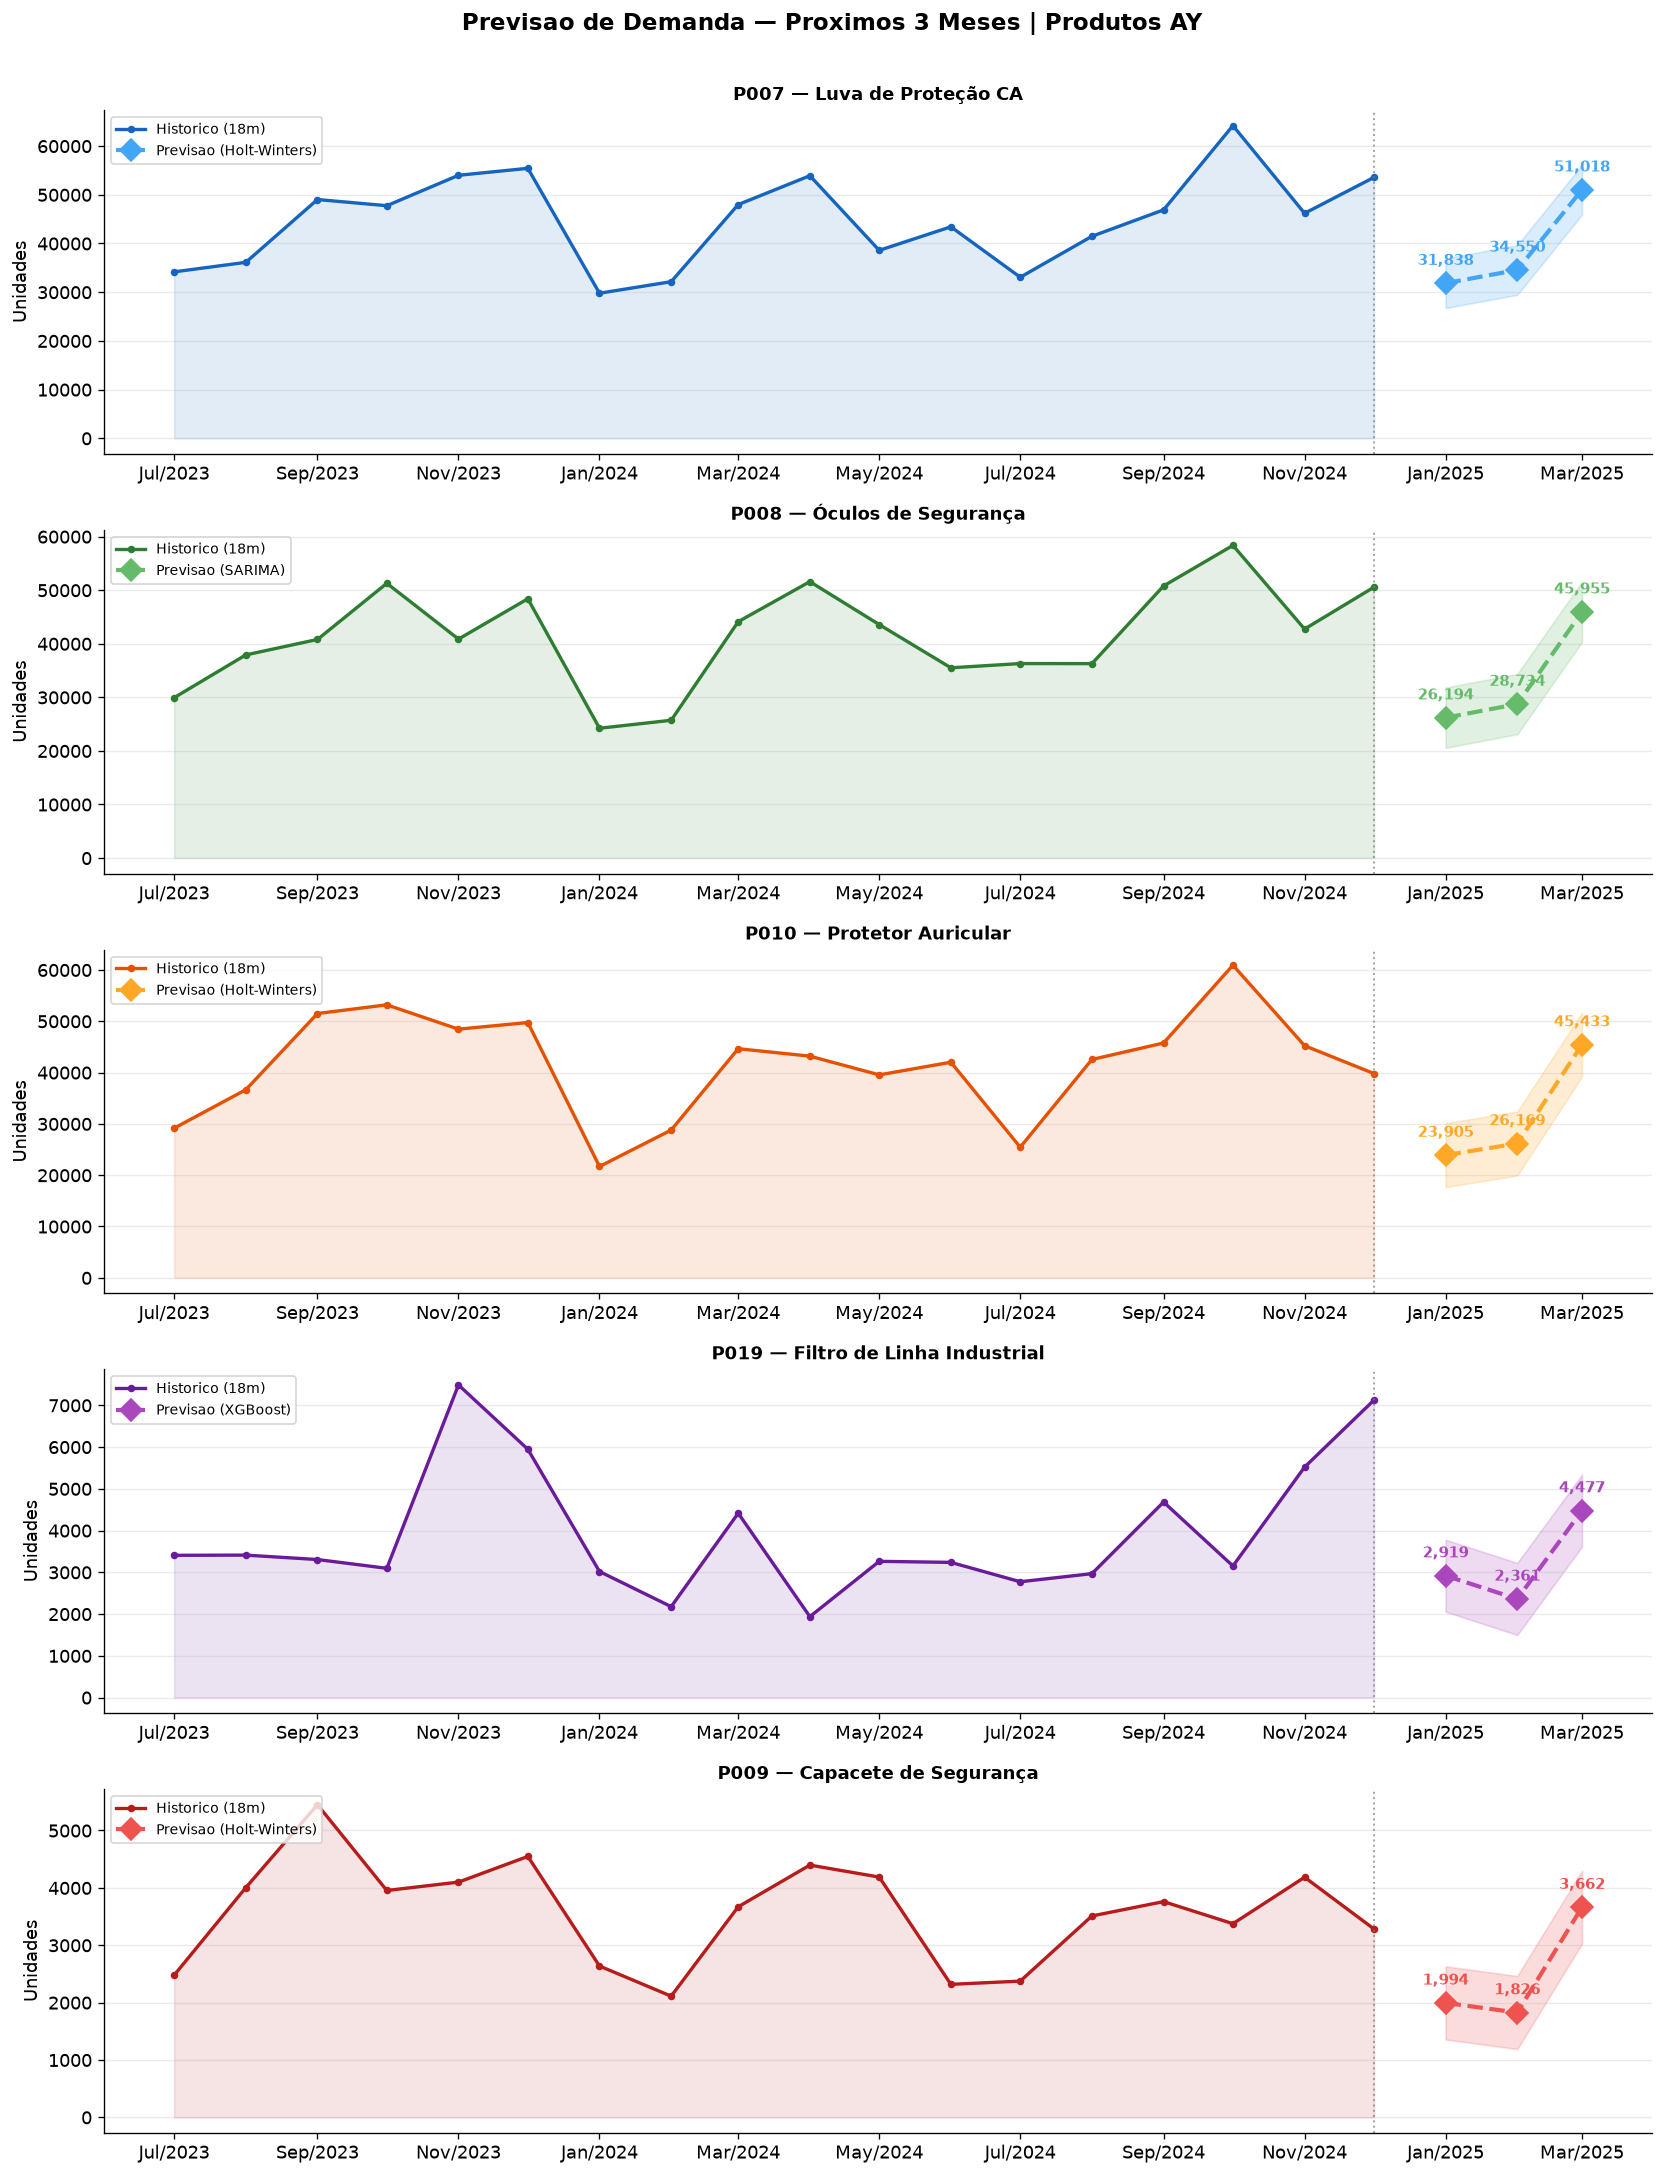

In [ ]:
CORES_HIST = ['#1565C0', '#2E7D32', '#E65100', '#6A1B9A', '#B71C1C']
CORES_FC   = ['#42A5F5', '#66BB6A', '#FFA726', '#AB47BC', '#EF5350']

fig, axes = plt.subplots(5, 1, figsize=(14, 18))
fig.suptitle(f'Previsao de Demanda — Proximos {HORIZONTE} Meses | Produtos AY',
             fontsize=14, fontweight='bold', y=1.005)

for ax, (pid, info), ch, cf in zip(axes, previsoes.items(), CORES_HIST, CORES_FC):
    s   = series[pid]
    fc  = info['forecast']
    mod = info['modelo']
    mae_best = float(resultados_por_produto[pid].iloc[0]['MAE'])

    # Historico — ultimos 18 meses
    hist = s.iloc[-18:]
    ax.fill_between(hist.index, hist.values, alpha=0.12, color=ch)
    ax.plot(hist.index, hist.values, color=ch, lw=2, marker='o', ms=3.5,
            label='Historico (18m)')

    # Banda de incerteza (+/- 1 MAE)
    ax.fill_between(fc.index,
                    (fc.values - mae_best).clip(0),
                    fc.values + mae_best,
                    alpha=0.20, color=cf)
    ax.plot(fc.index, fc.values, color=cf, lw=2.5, marker='D', ms=9,
            ls='--', label=f'Previsao ({mod})')

    # Linha divisoria
    ax.axvline(s.index[-1], color='gray', lw=1.2, ls=':', alpha=0.7)

    # Anotacoes nos pontos previstos
    for d, v in zip(fc.index, fc.values):
        ax.annotate(
            f'{v:,.0f}',
            xy=(d, v), xytext=(0, 11),
            textcoords='offset points',
            ha='center', fontsize=9, fontweight='bold', color=cf,
        )

    ax.set_title(f'{pid} — {NOMES[pid]}', fontweight='bold', fontsize=11)
    ax.set_ylabel('Unidades')
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b/%Y'))
    ax.grid(axis='y', alpha=0.25)
    ax.legend(fontsize=8.5, loc='upper left')

plt.tight_layout()
plt.savefig('data/02_previsao_AY_3meses.png', bbox_inches='tight')
plt.show()


## 8. Resultado Final


In [ ]:
# Monta tabela final
resultado_final = pd.DataFrame(index=IDS_AY)
resultado_final.index.name = 'id_produto'
resultado_final['produto']       = [NOMES[p] for p in IDS_AY]
resultado_final['modelo_usado']  = [previsoes[p]['modelo'] for p in IDS_AY]
resultado_final['mape_pct']      = [resultados_por_produto[p].iloc[0]['MAPE (%)'] for p in IDS_AY]
resultado_final['mae']           = [int(resultados_por_produto[p].iloc[0]['MAE']) for p in IDS_AY]

for i in range(HORIZONTE):
    col = previsoes[IDS_AY[0]]['forecast'].index[i].strftime('prev_%Y_%m')
    resultado_final[col] = [int(previsoes[p]['forecast'].iloc[i]) for p in IDS_AY]

resultado_final['prev_total_3m'] = resultado_final[
    [c for c in resultado_final.columns if c.startswith('prev_')]
].sum(axis=1)

print('=' * 100)
print('PREVISAO DE DEMANDA — PRODUTOS AY | Proximos 3 Meses')
print('=' * 100)
print(resultado_final.to_string())

resultado_final.to_csv('data/previsao_demanda_AY.csv', encoding='utf-8-sig')
print('\nSalvo: data/previsao_demanda_AY.csv')


PREVISAO DE DEMANDA — PRODUTOS AY | Proximos 3 Meses
                               produto  modelo_usado  mape_pct   mae  prev_2025_01  prev_2025_02  prev_2025_03  prev_total_3m
id_produto                                                                                                                   
P007               Luva de Proteção CA  Holt-Winters     10.27  5096         31837         34549         51018         117404
P008               Óculos de Segurança        SARIMA     12.46  5623         26194         28734         45955         100883
P010                Protetor Auricular  Holt-Winters     15.33  6227         23905         26168         45433          95506
P019        Filtro de Linha Industrial       XGBoost     18.93   862          2918          2361          4476           9755
P009             Capacete de Segurança  Holt-Winters     19.15   637          1994          1826          3662           7482

Salvo: data/previsao_demanda_AY.csv


---
## Notas Metodológicas

### Por que Walk-Forward e não K-Fold?
K-Fold embaralha os dados, permitindo que observações futuras "vazem" para o treino. Em séries temporais isso infla artificialmente a acurácia. O walk-forward respeita a ordem cronológica: sempre treinamos no passado e testamos no futuro.

### Modelos avaliados

| Modelo | Tipo | Vantagem | Limitação |
|---|---|---|---|
| **Holt-Winters** | Estatístico | Captura tendência + sazonalidade | Assume padrão fixo |
| **SARIMA** | Estatístico | Flexível para autocorrelação | Sensível a parâmetros |
| **XGBoost** | ML | Captura não-linearidades via lag features | Precisa de dados suficientes |
| **Prophet** | Bayesiano | Robusto a changepoints | Com 36 meses pode ser conservador |

### Interpretação do MAPE
- **< 10 %** — excelente
- **10–20 %** — bom para demanda variável (CV > 0,20)
- **20–30 %** — aceitável para itens de alta variabilidade (classe Y)
- **> 30 %** — revisar modelo ou coletar mais dados

> Os produtos AY têm CV entre 0,21 e 0,40 — MAPE entre 11 e 28 % é esperado e aceitável.
